# Space Lore Engine — Phase 3: teach your 100M model to write lore

**What this notebook does, in plain words:** it takes your pretrained 100M model (Step 2 of the LLM project) and the ~22,000 lore pieces written by the teacher (Phase 2), and fine-tunes the model on *tags → lore*. Afterwards your own model writes the lore — offline, on your GTX 1650 — and the notebook measures how well it follows the tags compared with before.

| Section | What happens | Time |
|---|---|---|
| 1 | Rebuild the training set from Phase 2's raw output with **fixed filters** (ship logs no longer need the author's name; repeated openings capped; leaked tags removed) | ~1 min |
| 2 | Tokenize, mix in ~10% of your Q&A data so the model keeps its chat skills | ~1 min |
| 3 | "Before": the base model on unseen tag lines | ~2 min |
| 4 | Fine-tune (3 epochs, best checkpoint kept) | ~20–40 min |
| 5 | "After": the same tag lines + automatic scores | ~5 min |
| 6 | Export `lore_forge_export.zip` → run `lore_forge.py` on your PC | ~1 min |

### How to run on Kaggle
1. *Add Input → Your Work → Notebooks*, attach **three** notebooks:
   - **lore data generation** (Phase 2) — provides `raw.jsonl`, `tags.jsonl`, `world_schema.json`
   - **transformer-v2** (pretraining) — provides `pretrained.pt`
   - **data-prep** — provides the tokenizer and your Q&A data
2. *Settings → Accelerator → GPU T4 x2* (one is used) or P100. Internet is not needed.
3. *Save Version → **Save & Run All***. You can close the browser.
4. When it finishes: *Output* → download **`lore_sft/lore_forge_export.zip`**.

### On your PC (GTX 1650)
```bat
cd %USERPROFILE%\Downloads
mkdir lore_forge && tar -xf lore_forge_export.zip -C lore_forge && cd lore_forge
python -m venv .venv
.venv\Scripts\activate
pip install torch --index-url https://download.pytorch.org/whl/cu126
pip install gradio tokenizers
python lore_forge.py
```

## 0. Setup and pre-flight checks

In [1]:
import os, sys, glob, json, math, time, random, shutil, re, hashlib, collections, importlib
import numpy as np
import torch
import torch.nn.functional as F
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

def find(pattern, env=None, local=None):
    cands = ([os.environ[env]] if env and os.environ.get(env) else []) + sorted(glob.glob(pattern, recursive=True))
    cands += [local] if local else []
    return next((c for c in cands if c and os.path.exists(c)), None)

LORE_DIR = find("/kaggle/input/**/lore_data/raw.jsonl", "LORE_DATA_RAW", "./lore_data/raw.jsonl")
LORE_DIR = os.path.dirname(LORE_DIR) if LORE_DIR else None
manifest_path = find("/kaggle/input/**/manifest.json", None, "./llm_data/manifest.json")
if os.environ.get("LLM_DATA"): manifest_path = os.path.join(os.environ["LLM_DATA"], "manifest.json")
pretrained_path = find("/kaggle/input/**/pretrained.pt", "PRETRAINED", "./tv2_run/pretrained.pt")
OUT_DIR = "/kaggle/working/lore_sft" if os.path.isdir("/kaggle/working") else os.path.abspath("./lore_sft")
os.makedirs(OUT_DIR, exist_ok=True)

problems = []
if not LORE_DIR: problems.append("Phase 2 output not found (lore_data/raw.jsonl) — Add Input → your lore data generation notebook")
if not manifest_path or not os.path.exists(manifest_path): problems.append("data-prep output not found (manifest.json) — Add Input → data-prep")
if not pretrained_path: problems.append("pretrained.pt not found — Add Input → transformer-v2 (the finished version)")
if not torch.cuda.is_available() and not SMOKE_TEST: problems.append("no GPU — Settings → Accelerator → GPU")
if not problems:
    for f in ("tags.jsonl", "world_schema.json"):
        if not os.path.exists(os.path.join(LORE_DIR, f)): problems.append(f"missing {f} in {LORE_DIR}")
if problems:
    raise RuntimeError("Pre-flight failed:\n- " + "\n- ".join(problems))

DATA_DIR = os.path.dirname(manifest_path)
manifest = json.load(open(manifest_path))
pre = torch.load(pretrained_path, map_location="cpu", weights_only=False)
assert pre["config"]["vocab_size"] == manifest["vocab_size"], "tokenizer / model vocab mismatch"
shutil.copy(os.path.join(LORE_DIR, "world_schema.json"), "world_schema.json")
dev = "cuda" if torch.cuda.is_available() else "cpu"
amp_dtype = (torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16) if dev == "cuda" else None
autocast = (lambda: torch.autocast("cuda", dtype=amp_dtype)) if amp_dtype else (lambda: torch.autocast("cpu", enabled=False))
print(f"lore data: {LORE_DIR}\ntokenizer/Q&A: {DATA_DIR}\nbase model: {pretrained_path} "
      f"({pre.get('tokens', 0)/1e9:.2f}B pretraining tokens)\ndevice: {dev} | amp: {amp_dtype} | output: {OUT_DIR}")

lore data: /kaggle/input/notebooks/prashant554/lore-data-gen/lore_data
tokenizer/Q&A: /kaggle/input/notebooks/prashant554/data-prep/llm_data
base model: /kaggle/input/notebooks/prashant554/transformer-v2/tv2_run/pretrained.pt (1.50B pretraining tokens)
device: cuda | amp: torch.float16 | output: /kaggle/working/lore_sft


In [2]:
%%writefile model_v2.py
"""model_v2.py — a ~100M GPT with modern (Llama-style) parts.

Shared by the pretraining notebook, the fine-tuning notebook and chat_app.py.
For Mamba / Jamba later, only this file changes; train.py and the notebooks stay the same.

Parts (each explained in the notebook):
  RMSNorm        normalise by root-mean-square (no mean subtraction, no bias)
  RoPE           rotary position embeddings
  GQA attention  12 query heads share 4 key/value heads -> 3x smaller KV-cache
  QK-norm        RMSNorm on queries and keys -> attention scores can't blow up in fp16
  SwiGLU MLP     gated feed-forward: down( silu(gate(x)) * up(x) )
"""
import math
from dataclasses import dataclass, asdict

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class ModelConfig:
    vocab_size: int = 32768
    n_layer: int = 12
    n_head: int = 12
    n_kv_head: int = 4
    d_model: int = 768
    ffn_hidden: int = 2048
    block_size: int = 1024          # training context length
    max_pos: int = 4096             # RoPE table length (lets benchmarks go past block_size)
    rope_base: float = 10000.0
    qk_norm: bool = True
    dropout: float = 0.0
    norm_eps: float = 1e-5

    @property
    def head_dim(self):
        return self.d_model // self.n_head

    def validate(self):
        assert self.d_model % self.n_head == 0, "d_model must be divisible by n_head"
        assert self.n_head % self.n_kv_head == 0, "n_head must be divisible by n_kv_head"
        assert self.head_dim % 2 == 0, "RoPE needs an even head_dim"
        assert self.max_pos >= self.block_size
        return self

    def to_dict(self):
        return asdict(self)


class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return xf.type_as(x) * self.weight


def build_rope_cache(max_pos, head_dim, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))
    angles = torch.outer(torch.arange(max_pos).float(), inv_freq)        # (max_pos, hd/2)
    return angles.cos(), angles.sin()


def apply_rope(x, cos, sin):
    # x: (B, H, T, hd); cos/sin: (T, hd/2) — rotate each (even, odd) pair of dims
    x1, x2 = x[..., 0::2].float(), x[..., 1::2].float()
    out = torch.stack((x1 * cos - x2 * sin, x1 * sin + x2 * cos), dim=-1).flatten(-2)
    return out.type_as(x)


class Attention(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.n_head, self.n_kv, self.hd = cfg.n_head, cfg.n_kv_head, cfg.head_dim
        self.q = nn.Linear(cfg.d_model, cfg.n_head * self.hd, bias=False)
        self.kv = nn.Linear(cfg.d_model, 2 * cfg.n_kv_head * self.hd, bias=False)
        self.o = nn.Linear(cfg.n_head * self.hd, cfg.d_model, bias=False)
        self.o.SCALE_INIT = True
        self.q_norm = RMSNorm(self.hd, cfg.norm_eps) if cfg.qk_norm else nn.Identity()
        self.k_norm = RMSNorm(self.hd, cfg.norm_eps) if cfg.qk_norm else nn.Identity()
        self.dropout = cfg.dropout

    def forward(self, x, rope, kv_cache=None):
        B, T, _ = x.shape
        q = self.q(x).view(B, T, self.n_head, self.hd).transpose(1, 2)              # (B, H, T, hd)
        kv = self.kv(x).view(B, T, 2, self.n_kv, self.hd)
        k, v = kv[:, :, 0].transpose(1, 2), kv[:, :, 1].transpose(1, 2)             # (B, KV, T, hd)
        q, k = self.q_norm(q), self.k_norm(k)

        past = 0 if (kv_cache is None or kv_cache["k"] is None) else kv_cache["k"].size(2)
        assert past == 0 or T == 1, "with a KV-cache: feed the prompt once, then one token at a time"
        cos, sin = rope
        q = apply_rope(q, cos[past:past + T], sin[past:past + T])
        k = apply_rope(k, cos[past:past + T], sin[past:past + T])
        if kv_cache is not None:                       # the cache stores only the 4 KV heads
            if past:
                k = torch.cat([kv_cache["k"], k], dim=2)
                v = torch.cat([kv_cache["v"], v], dim=2)
            kv_cache["k"], kv_cache["v"] = k, v

        rep = self.n_head // self.n_kv                 # each KV head serves `rep` query heads
        if rep > 1:
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=(past == 0 and T > 1),
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.o(y.transpose(1, 2).contiguous().view(B, T, -1))


class SwiGLU(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.gate = nn.Linear(cfg.d_model, cfg.ffn_hidden, bias=False)
        self.up = nn.Linear(cfg.d_model, cfg.ffn_hidden, bias=False)
        self.down = nn.Linear(cfg.ffn_hidden, cfg.d_model, bias=False)
        self.down.SCALE_INIT = True
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        return self.drop(self.down(F.silu(self.gate(x)) * self.up(x)))


class Block(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.norm1, self.attn = RMSNorm(cfg.d_model, cfg.norm_eps), Attention(cfg)
        self.norm2, self.mlp = RMSNorm(cfg.d_model, cfg.norm_eps), SwiGLU(cfg)

    def forward(self, x, rope, kv_cache=None):
        x = x + self.attn(self.norm1(x), rope, kv_cache)     # communication
        x = x + self.mlp(self.norm2(x))                       # computation
        return x


class GPT(nn.Module):
    arch = "transformer_v2"

    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg.validate()
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.norm_f = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight                  # weight tying
        cos, sin = build_rope_cache(cfg.max_pos, cfg.head_dim, cfg.rope_base)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            std = 0.02 * ((2 * self.cfg.n_layer) ** -0.5 if getattr(m, "SCALE_INIT", False) else 1.0)
            nn.init.normal_(m.weight, mean=0.0, std=std)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def num_params(self):
        return sum(p.numel() for p in self.parameters())

    def new_cache(self):
        return [{"k": None, "v": None} for _ in self.blocks]

    def forward(self, idx, targets=None, kv_caches=None, last_only=False, z_loss=0.0):
        B, T = idx.shape
        past = 0 if (kv_caches is None or kv_caches[0]["k"] is None) else kv_caches[0]["k"].size(2)
        assert past + T <= self.cfg.max_pos, f"sequence {past + T} > max_pos {self.cfg.max_pos}"
        x = self.drop(self.tok_emb(idx))
        rope = (self.rope_cos, self.rope_sin)
        for i, blk in enumerate(self.blocks):
            x = blk(x, rope, None if kv_caches is None else kv_caches[i])
        x = self.norm_f(x)
        if targets is None:
            return self.lm_head(x[:, -1:, :] if last_only else x), None
        logits = self.lm_head(x).float()
        loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-100)
        if z_loss > 0:   # keeps logits small -> stable fp16 training (PaLM trick)
            mask = (targets.view(-1) != -100)
            lse = torch.logsumexp(logits.view(-1, logits.size(-1)), dim=-1)
            loss = loss + z_loss * (lse[mask] ** 2).mean()
        return logits, loss

    def configure_optimizer(self, lr, weight_decay, betas=(0.9, 0.95), fused=False):
        params = [p for p in self.parameters() if p.requires_grad]
        decay = [p for p in params if p.dim() >= 2]
        no_decay = [p for p in params if p.dim() < 2]
        groups = [{"params": decay, "weight_decay": weight_decay},
                  {"params": no_decay, "weight_decay": 0.0}]
        return torch.optim.AdamW(groups, lr=lr, betas=betas, eps=1e-8, fused=fused)

    # ---------------------------------------------------------------- generation
    @staticmethod
    def sample_next(logits, temperature=1.0, top_k=None, top_p=None, repetition_penalty=1.0, history=None):
        logits = logits.float()
        if repetition_penalty != 1.0 and history is not None and history.numel():
            prev = logits.gather(1, history)
            logits = logits.scatter(1, history, torch.where(prev > 0, prev / repetition_penalty,
                                                            prev * repetition_penalty))
        if temperature <= 0:
            return logits.argmax(dim=-1, keepdim=True)
        logits = logits / temperature
        if top_k:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits = logits.masked_fill(logits < v[:, [-1]], float("-inf"))
        probs = F.softmax(logits, dim=-1)
        if top_p and top_p < 1.0:
            sp, si = torch.sort(probs, descending=True)
            cut = (sp.cumsum(-1) - sp) > top_p
            sp = sp.masked_fill(cut, 0.0)
            probs = torch.zeros_like(probs).scatter(1, si, sp)
            probs = probs / probs.sum(-1, keepdim=True)
        return torch.multinomial(probs, num_samples=1)

    @torch.no_grad()
    def generate_stream(self, idx, max_new_tokens, temperature=0.8, top_k=50, top_p=None,
                        repetition_penalty=1.0, stop_ids=()):
        """Yields one new token id at a time (batch size 1), using the KV-cache."""
        assert idx.size(0) == 1, "generate_stream is for a single sequence"
        max_new_tokens = min(max_new_tokens, self.cfg.max_pos - idx.size(1))
        caches = self.new_cache()
        logits, _ = self(idx, kv_caches=caches, last_only=True)          # prefill the prompt
        generated = idx.new_zeros((1, 0))
        for _ in range(max_new_tokens):
            nxt = self.sample_next(logits[:, -1, :], temperature, top_k, top_p, repetition_penalty,
                                   generated[:, -64:])
            tid = int(nxt)
            if tid in stop_ids:
                return
            yield tid
            generated = torch.cat([generated, nxt], dim=1)
            logits, _ = self(nxt, kv_caches=caches, last_only=True)

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=50, top_p=None,
                 repetition_penalty=1.0, stop_ids=(), use_cache=True):
        """Batched generation. Returns idx with new tokens appended (stops early only if all rows hit a stop id)."""
        if not use_cache:
            for _ in range(max_new_tokens):
                logits, _ = self(idx[:, -self.cfg.max_pos:], last_only=True)
                idx = torch.cat([idx, self.sample_next(logits[:, -1, :], temperature, top_k, top_p)], dim=1)
            return idx
        max_new_tokens = min(max_new_tokens, self.cfg.max_pos - idx.size(1))
        caches = self.new_cache()
        logits, _ = self(idx, kv_caches=caches, last_only=True)
        done = torch.zeros(idx.size(0), dtype=torch.bool, device=idx.device)
        stop = torch.tensor(list(stop_ids) or [-1], device=idx.device)
        for _ in range(max_new_tokens):
            nxt = self.sample_next(logits[:, -1, :], temperature, top_k, top_p)
            idx = torch.cat([idx, nxt], dim=1)
            done |= torch.isin(nxt.squeeze(1), stop)
            if done.all():
                break
            logits, _ = self(nxt, kv_caches=caches, last_only=True)
        return idx


def build_model(cfg_dict):
    return GPT(ModelConfig(**cfg_dict))


def load_exported(path, device="cpu", dtype=None):
    """Load a file written by the fine-tuning notebook's export step."""
    ck = torch.load(path, map_location="cpu", weights_only=True)
    model = build_model(ck["config"])
    model.load_state_dict(ck["model"])
    model = model.to(device)
    if dtype is not None:
        model = model.to(dtype)
        model.rope_cos, model.rope_sin = model.rope_cos.float(), model.rope_sin.float()   # keep RoPE precise
    return model.eval(), ck

Writing model_v2.py


In [3]:
%%writefile lore_schema.py
#!/usr/bin/env python3
"""lore_schema.py — load, validate and sample the Space Lore Engine world schema.

Plain words: the schema (world_schema.json) lists the kinds of things in the galaxy (planets, factions, ...)
and the properties each can have. This tool turns it into random, consistent "tag lines" such as

    type: planet | name: Veyra-7 | climate: ice | size: medium | life: none | danger: high | mood: eerie | length: short

Phase 2 sends those tags to Gemini to write the lore; Phase 3 teaches your model tags -> lore.

Usage:
    python lore_schema.py --validate                 # check the schema, exit 1 on problems
    python lore_schema.py --sample 5 --seed 1        # print random tag lines
    python lore_schema.py --stats                    # how many combinations exist per type
    python lore_schema.py --selftest                 # validate + sample 20k entities + check every rule
"""
import argparse
import json
import math
import os
import random
import re
import sys

HERE = os.path.dirname(os.path.abspath(__file__))
DEFAULT_SCHEMA = os.path.join(HERE, "world_schema.json")
NAME_STYLES = {"planet", "system", "faction", "species", "ship", "artifact", "person", "quest", "station"}


# ---------------------------------------------------------------- loading + validation
def load_schema(path=DEFAULT_SCHEMA):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def _is_special(spec):
    return isinstance(spec, str) and spec.startswith("@")


def validate_schema(S):
    """Returns a list of problems (empty list = valid)."""
    p = []
    for key in ("universe", "lengths", "type_weights", "types", "names", "link_probability"):
        if key not in S:
            p.append(f"missing top-level key '{key}'")
    if p:
        return p
    types = S["types"]
    if set(S["type_weights"]) != set(types):
        p.append(f"type_weights keys {sorted(S['type_weights'])} != types {sorted(types)}")
    for name, (lo, hi) in S["lengths"].items():
        if not 0 < lo < hi:
            p.append(f"length '{name}' must be 0 < min < max")
    if not 0 <= S["link_probability"] <= 1:
        p.append("link_probability must be in [0, 1]")
    for t, T in types.items():
        for k in ("description", "name_style", "fields", "optional", "links", "rules"):
            if k not in T:
                p.append(f"{t}: missing '{k}'")
        if p:
            continue
        if T["name_style"] not in NAME_STYLES:
            p.append(f"{t}: unknown name_style '{T['name_style']}'")
        for f, spec in T["fields"].items():
            if _is_special(spec):
                if not (spec == "@character" or re.fullmatch(r"@int:\d+:\d+", spec)):
                    p.append(f"{t}.{f}: unknown special spec '{spec}'")
            elif not (isinstance(spec, list) and spec and all(isinstance(v, str) for v in spec)):
                p.append(f"{t}.{f}: must be a non-empty list of strings")
            elif len(set(spec)) != len(spec):
                p.append(f"{t}.{f}: duplicate values")
        if "mood" not in T["fields"]:
            p.append(f"{t}: every type needs a 'mood' field (it drives the writing style)")
        for f in T["optional"]:
            if f not in T["fields"]:
                p.append(f"{t}: optional field '{f}' is not a field")
        for rel, target in T["links"].items():
            if target not in types:
                p.append(f"{t}: link '{rel}' points to unknown type '{target}'")
        for i, r in enumerate(T["rules"]):
            for side in ("if", "then"):
                for f, v in r.get(side, {}).items():
                    if f not in T["fields"] or _is_special(T["fields"][f]):
                        p.append(f"{t} rule {i}: '{f}' is not a list field")
                        continue
                    vals = v if isinstance(v, list) else [v]
                    bad = [x for x in vals if x not in T["fields"][f]]
                    if bad:
                        p.append(f"{t} rule {i}: values {bad} not allowed for '{f}'")
    N = S["names"]
    for k in ("syllables_start", "syllables_mid", "syllables_end", "first_names", "ai_names"):
        if not N.get(k):
            p.append(f"names.{k} is empty")
    for k, v in N.items():
        if k.endswith("_pattern"):
            for pat in v:
                if not re.search(r"\{[NAB]\}", pat):
                    p.append(f"names.{k}: pattern '{pat}' has no {{N}}/{{A}}/{{B}} slot")
    return p


# ---------------------------------------------------------------- names
class NameGen:
    """Invents original names from syllables, so the training data never borrows franchise names."""

    def __init__(self, S, rng):
        self.N, self.rng, self.used = S["names"], rng, set()
        self.banned = {b.lower() for b in S["universe"]["banned_terms"]}

    def _word(self):
        N, r = self.N, self.rng
        w = r.choice(N["syllables_start"]) + ("" if r.random() < 0.35 else r.choice(N["syllables_mid"]))
        return w + r.choice(N["syllables_end"])

    def _fill(self, pattern):
        N, r = self.N, self.rng
        return (pattern.replace("{N}", self._word()).replace("{A}", r.choice(N["ship_words_a"]))
                .replace("{B}", r.choice(N["ship_words_b"])))

    def _make(self, style, role=None):
        N, r = self.N, self.rng
        if style == "planet":
            return self._word() + r.choice(N["planet_suffix"])
        if style == "system":
            return (r.choice(N["system_prefix"]) + self._word() + r.choice(N["system_suffix"])).strip()
        if style == "species":
            return "the " + self._word() + r.choice(["i", "ans", "ari", "", "eth"])
        if style == "person":
            if role == "AI companion":
                return r.choice(N["ai_names"]) + ("" if r.random() < 0.5 else f"-{r.randint(2, 99)}")
            return f"{r.choice(N['first_names'])} {self._word()}"
        key = {"faction": "faction_pattern", "ship": "ship_pattern", "artifact": "artifact_pattern",
               "station": "station_pattern", "quest": "quest_pattern"}[style]
        return self._fill(r.choice(N[key]))

    def new(self, style, role=None, max_tries=200):
        for _ in range(max_tries):
            name = self._make(style, role)
            low = name.lower()
            if low not in self.used and not any(b in low for b in self.banned):
                self.used.add(low)
                return name
        raise RuntimeError(f"could not find a new unique '{style}' name — add more syllables/patterns")


# ---------------------------------------------------------------- sampling
def _rule_ok(entity, rule):
    if all(entity.get(f) == v for f, v in rule["if"].items()):
        return all(entity.get(f) in (v if isinstance(v, list) else [v]) for f, v in rule["then"].items())
    return True


def sample_entity(S, rng, names, etype=None, optional_p=0.6):
    """One random, rule-consistent entity as a dict (insertion order = tag order)."""
    if etype is None:
        types, w = zip(*S["type_weights"].items())
        etype = rng.choices(types, weights=w)[0]
    T = S["types"][etype]
    for _ in range(100):                                  # rejection sampling until all rules hold
        fields = {}
        for f, spec in T["fields"].items():
            if f in T["optional"] and rng.random() > optional_p:
                continue
            if spec == "@character":
                fields[f] = None                          # filled after the rules are satisfied
            elif isinstance(spec, str) and spec.startswith("@int:"):
                lo, hi = map(int, spec.split(":")[1:])
                fields[f] = str(rng.randint(lo, hi))
            else:
                fields[f] = rng.choice(spec)
        if all(_rule_ok(fields, r) for r in T["rules"]):
            break
    else:
        raise RuntimeError(f"{etype}: rules too strict, no valid combination found in 100 tries")

    e = {"type": etype, "name": names.new(T["name_style"], role=fields.get("role"))}
    for f, v in fields.items():
        e[f] = names.new("person") if v is None else v
    for rel, target in T["links"].items():                # optional references to other entities
        if rng.random() < S["link_probability"]:
            e[rel] = names.new(S["types"][target]["name_style"])
    e["length"] = rng.choice(list(S["lengths"]))
    return e


def to_tags(entity):
    return " | ".join(f"{k}: {v}" for k, v in entity.items())


def parse_tags(line):
    out = {}
    for part in line.split(" | "):
        k, _, v = part.partition(": ")
        out[k.strip()] = v.strip()
    return out


def word_range(S, entity):
    return S["lengths"][entity["length"]]


def check_lore(S, entity, text):
    """Problems with a generated text for this entity (used to filter Phase 2 data). Empty list = OK."""
    probs = []
    low = text.lower()
    words = len(text.split())
    lo, hi = word_range(S, entity)
    if not (lo * 0.8 <= words <= hi * 1.25):
        probs.append(f"length {words} words, expected {lo}-{hi}")
    if entity["name"].lower().removeprefix("the ") not in text.lower():
        probs.append(f"name '{entity['name']}' missing")
    for rel in S["types"][entity["type"]]["links"]:            # linked names must appear too
        if rel in entity and entity[rel].lower().removeprefix("the ") not in text.lower():
            probs.append(f"{rel} '{entity[rel]}' missing")
    if entity["type"] == "ship_log":       # first-person log: the author says "I", not their own name
        if "day" in entity and not re.match(rf"\s*day\s*{entity['day']}\b", low):
            probs.append(f"log does not start with 'Day {entity['day']}'")
        if not re.search(r"\b(i|i'm|i've|my|me|we|our|us)\b", low):
            probs.append("log is not written in first person")
    hits = [b for b in S["universe"]["banned_terms"] if re.search(rf"\b{re.escape(b.lower())}\b", low)]
    if hits:
        probs.append(f"franchise terms {hits}")
    return probs


def combinations(S, etype):
    T = S["types"][etype]
    n = 1
    for f, spec in T["fields"].items():
        k = len(spec) if isinstance(spec, list) else (int(spec.split(":")[2]) - int(spec.split(":")[1]) + 1
                                                       if spec.startswith("@int:") else 1)
        n *= k + (1 if f in T["optional"] else 0)
    return n * len(S["lengths"])


# ---------------------------------------------------------------- self-test
def selftest(S, n=20000, seed=0):
    probs = validate_schema(S)
    assert not probs, probs
    rng = random.Random(seed)
    names = NameGen(S, rng)
    counts = {t: 0 for t in S["types"]}
    for _ in range(n):
        e = sample_entity(S, rng, names)
        T = S["types"][e["type"]]
        counts[e["type"]] += 1
        for r in T["rules"]:
            assert _rule_ok(e, r), (e, r)
        assert parse_tags(to_tags(e)) == e, "tag round-trip failed"
        for f in T["fields"]:
            assert f in e or f in T["optional"], (f, e)
    exp = {t: n * w / sum(S["type_weights"].values()) for t, w in S["type_weights"].items()}
    for t in counts:
        assert abs(counts[t] - exp[t]) < 0.1 * exp[t] + 50, (t, counts[t], exp[t])
    assert len(names.used) > 0.99 * n, "names are not unique enough"
    good = {"type": "planet", "name": "Veyra-7", "length": "short"}
    assert check_lore(S, good, "Veyra-7 is " + "cold " * 70) == []
    assert check_lore(S, good, "A planet. " * 5)            # too short + no name
    assert check_lore(S, good, "Veyra-7 has a Jedi temple. " + "x " * 70)
    linked = {"type": "faction", "name": "the Drenex Syndicate", "homeworld": "Quaix", "length": "short"}
    assert check_lore(S, linked, "Drenex Syndicate rules. " + "y " * 70), "missing link not caught"
    assert check_lore(S, linked, "Drenex Syndicate rules from Quaix. " + "y " * 70) == []
    log = {"type": "ship_log", "name": "The Long Quiet", "author": "Mara Velor", "day": "41", "length": "short"}
    assert check_lore(S, log, "Day 41. The Long Quiet drifts. I checked the drive again. " + "z " * 60) == []
    assert check_lore(S, log, "Mara Velor checked the Long Quiet drive. " + "z " * 60), "bad log not caught"
    print(f"selftest OK: {n:,} entities, all rules hold, {len(names.used):,} unique names, "
          f"type mix {dict(sorted(counts.items(), key=lambda x: -x[1]))}")


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--schema", default=DEFAULT_SCHEMA)
    ap.add_argument("--validate", action="store_true")
    ap.add_argument("--sample", type=int, default=0)
    ap.add_argument("--type", default=None)
    ap.add_argument("--seed", type=int, default=None)
    ap.add_argument("--stats", action="store_true")
    ap.add_argument("--selftest", action="store_true")
    a = ap.parse_args()
    S = load_schema(a.schema)
    probs = validate_schema(S)
    if probs:
        print("Schema problems:\n- " + "\n- ".join(probs)); sys.exit(1)
    if a.validate:
        print(f"schema OK: {len(S['types'])} entity types")
    if a.stats:
        total = 0
        for t in S["types"]:
            c = combinations(S, t); total += c
            print(f"  {t:12s} {len(S['types'][t]['fields'])} fields  ~10^{math.log10(c):.1f} tag combinations")
        print(f"  total ~10^{math.log10(total):.1f} combinations (before names) — far more than 20k examples")
    if a.sample:
        rng = random.Random(a.seed)
        names = NameGen(S, rng)
        for _ in range(a.sample):
            print(to_tags(sample_entity(S, rng, names, a.type)))
    if a.selftest:
        selftest(S)
    if not (a.validate or a.stats or a.sample or a.selftest):
        ap.print_help()


if __name__ == "__main__":
    main()

Writing lore_schema.py


In [4]:
%%writefile lore_forge.py
#!/usr/bin/env python3
"""lore_forge.py — generate space lore with your own 100M model (GTX 1650, any GPU, or CPU).

Run from the unzipped export folder:
    python lore_forge.py            # web app at http://127.0.0.1:7860
    python lore_forge.py --cli      # print a few random lore pieces in the terminal
Options: --model_dir DIR  --cpu  --port 7860  --share
"""
import argparse
import os
import random
import sys
import threading
import time

HERE = os.path.dirname(os.path.abspath(__file__))


# ---------------------------------------------------------------- pre-flight
def preflight(args):
    d = os.path.abspath(args.model_dir)
    problems = [f"missing {f} in {d}" for f in ("model.pt", "tokenizer.json", "model_v2.py", "lore_schema.py", "world_schema.json")
                if not os.path.exists(os.path.join(d, f))]
    for mod, hint in (("torch", "pip install torch --index-url https://download.pytorch.org/whl/cu126"),
                      ("tokenizers", "pip install tokenizers")):
        try:
            __import__(mod)
        except ImportError:
            problems.append(f"{mod} not installed: {hint}")
    if not args.cli:
        try:
            import gradio  # noqa: F401
        except ImportError:
            problems.append("gradio not installed: pip install gradio   (or run with --cli)")
    if problems:
        print("Pre-flight failed:\n- " + "\n- ".join(problems)); sys.exit(1)
    import torch
    device = "cuda" if (torch.cuda.is_available() and not args.cpu) else "cpu"
    if device == "cuda":
        p = torch.cuda.get_device_properties(0); print(f"GPU: {p.name} ({p.total_memory/1e9:.1f} GB)")
    elif not args.cpu:
        print("No CUDA GPU visible — using the CPU (fine for a 100M model).")
    return d, device


# ---------------------------------------------------------------- engine
class LoreEngine:
    def __init__(self, model_dir, device):
        import torch
        from tokenizers import Tokenizer
        sys.path.insert(0, model_dir)
        import lore_schema
        from model_v2 import load_exported
        self.torch, self.device, self.ls = torch, device, lore_schema
        self.model, meta = load_exported(os.path.join(model_dir, "model.pt"), device,
                                         torch.float16 if device == "cuda" else torch.float32)
        self.tok = Tokenizer.from_file(os.path.join(model_dir, "tokenizer.json"))
        sp = meta["special_tokens"]
        self.USER, self.ASSIST, self.END, self.EOT = sp["<|user|>"], sp["<|assistant|>"], sp["<|end|>"], sp["<|endoftext|>"]
        self.NL = self.tok.encode("\n").ids
        self.S = lore_schema.load_schema(os.path.join(model_dir, "world_schema.json"))
        self.rng = random.Random()
        self.names = lore_schema.NameGen(self.S, self.rng)
        self.lock = threading.Lock()
        print(f"Loaded {self.model.num_params()/1e6:.0f}M-parameter lore model on {device}")

    # --- entities
    def random_entity(self, etype):
        return self.ls.sample_entity(self.S, self.rng, self.names, etype)

    def make_entity(self, etype, name=None, links=None, length=None):
        """Random entity of a type, with chosen name/links, in the exact tag order used in training."""
        base = self.random_entity(etype)
        T = self.S["types"][etype]
        e = {"type": etype, "name": name or base["name"]}
        for f in T["fields"]:
            if f in base:
                e[f] = base[f]
        for rel in T["links"]:
            if links and rel in links:
                e[rel] = links[rel]
        e["length"] = length or base["length"]
        return e

    # --- generation
    def stream(self, tags, max_new=260, temperature=0.8, top_k=50, top_p=0.9, repetition_penalty=1.1):
        torch = self.torch
        ids = [self.USER] + self.NL + self.tok.encode(tags).ids + [self.END] + self.NL + [self.ASSIST] + self.NL
        idx = torch.tensor([ids], device=self.device)
        out = []
        with self.lock:
            for t in self.model.generate_stream(idx, int(max_new), temperature=float(temperature), top_k=int(top_k),
                                                top_p=float(top_p), repetition_penalty=float(repetition_penalty),
                                                stop_ids=(self.END, self.EOT)):
                out.append(t)
                yield self.tok.decode(out).strip()

    def generate(self, tags, **kw):
        text = ""
        for text in self.stream(tags, **kw):
            pass
        return text

    def check(self, tags, text):
        try:
            return self.ls.check_lore(self.S, self.ls.parse_tags(tags), text)
        except Exception as e:  # malformed hand-edited tags
            return [f"could not check tags ({e})"]


def field_help(S, etype):
    T = S["types"][etype]
    lines = [f"**{etype}** — {T['description']}", ""]
    for f, spec in T["fields"].items():
        vals = ", ".join(spec) if isinstance(spec, list) else ("a person's name" if spec == "@character" else "a number")
        lines.append(f"- `{f}`{' (optional)' if f in T['optional'] else ''}: {vals}")
    if T["links"]:
        lines.append("- links (optional): " + ", ".join(f"`{r}` → a {t} name" for r, t in T["links"].items()))
    lines.append("- `length`: short or medium")
    return "\n".join(lines)


# ---------------------------------------------------------------- star system
def star_system_items(engine, n_planets_max=4):
    """A consistent set of tag lines: one system, its planets, factions, a species and a station."""
    system = engine.make_entity("star_system", length="medium")
    n = min(int(system.get("planet_count", 3)), n_planets_max)
    planets = [engine.make_entity("planet", links={"located_in": system["name"]}) for _ in range(n)]
    homes = [p["name"] for p in planets] or [engine.names.new("planet")]
    items = [("Star system", system)] + [(f"Planet {i+1}", p) for i, p in enumerate(planets)]
    items += [(f"Faction {i+1}", engine.make_entity("faction", links={"homeworld": engine.rng.choice(homes)})) for i in range(2)]
    items.append(("Native species", engine.make_entity("species", links={"homeworld": engine.rng.choice(homes)})))
    items.append(("Station", engine.make_entity("station", links={"located_in": system["name"]})))
    return system, items


# ---------------------------------------------------------------- web UI
def build_ui(engine):
    import gradio as gr
    types = list(engine.S["types"])
    os.makedirs(os.path.join(HERE, "codex"), exist_ok=True)

    def randomize(etype):
        return engine.ls.to_tags(engine.random_entity(etype)), field_help(engine.S, etype)

    def forge(tags, temperature, top_p, rep, max_new):
        if not tags.strip():
            yield "Pick a type and press 🎲 Randomize (or type tags).", ""; return
        text = ""
        for text in engine.stream(tags.strip(), max_new, temperature, 50, top_p, rep):
            yield text, ""
        probs = engine.check(tags.strip(), text)
        yield text, ("✅ follows the tags" if not probs else "⚠ " + "; ".join(probs))

    def forge_system(temperature, top_p, rep):
        system, items = star_system_items(engine)
        md = f"# The {system['name']}\n"
        yield md, None
        for title, e in items:
            tags = engine.ls.to_tags(e)
            md += f"\n## {title}: {e['name']}\n<sub>`{tags}`</sub>\n\n"
            text = ""
            for text in engine.stream(tags, 260, temperature, 50, top_p, rep):
                yield md + text, None
            md += text + "\n"
        path = os.path.join(HERE, "codex", f"{system['name'].replace(' ', '_')}_{time.strftime('%Y%m%d_%H%M%S')}.md")
        with open(path, "w", encoding="utf-8") as f:
            f.write(md)
        yield md, path

    with gr.Blocks(title="Lore Forge") as demo:
        gr.Markdown("# 🌌 Lore Forge\nSpace lore written by your own 100M-parameter model, trained from scratch.")
        with gr.Accordion("Generation settings", open=False):
            temperature = gr.Slider(0.1, 1.5, 0.8, step=0.05, label="Temperature (higher = wilder)")
            top_p = gr.Slider(0.5, 1.0, 0.9, step=0.05, label="Top-p")
            rep = gr.Slider(1.0, 1.5, 1.1, step=0.01, label="Repetition penalty")
            max_new = gr.Slider(64, 400, 260, step=8, label="Max length (tokens)")

        with gr.Tab("Forge one"):
            with gr.Row():
                etype = gr.Dropdown(types, value="planet", label="Type")
                roll = gr.Button("🎲 Randomize")
            tags = gr.Textbox(label="Tags (edit freely)", lines=2)
            go = gr.Button("✨ Forge", variant="primary")
            out = gr.Textbox(label="Lore", lines=10)
            status = gr.Markdown()
            help_md = gr.Markdown(field_help(engine.S, "planet"))
            roll.click(randomize, etype, [tags, help_md])
            etype.change(randomize, etype, [tags, help_md])
            go.click(forge, [tags, temperature, top_p, rep, max_new], [out, status])

        with gr.Tab("Generate a star system"):
            gr.Markdown("One click: a star system, its planets, two factions, a native species and a station — "
                        "all linked by name. The result is saved as a Markdown codex in the `codex/` folder.")
            sys_btn = gr.Button("🪐 Generate star system", variant="primary")
            codex = gr.Markdown()
            codex_file = gr.File(label="Codex file")
            sys_btn.click(forge_system, [temperature, top_p, rep], [codex, codex_file])

        demo.load(randomize, etype, [tags, help_md])
    return demo


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--model_dir", default=HERE)
    ap.add_argument("--cli", action="store_true", help="print random lore in the terminal")
    ap.add_argument("--cpu", action="store_true")
    ap.add_argument("--port", type=int, default=7860)
    ap.add_argument("--share", action="store_true")
    ap.add_argument("--no_browser", action="store_true")
    args = ap.parse_args()
    model_dir, device = preflight(args)
    engine = LoreEngine(model_dir, device)
    if args.cli:
        for etype in ("planet", "faction", "ship_log"):
            tags = engine.ls.to_tags(engine.random_entity(etype))
            text = engine.generate(tags)
            probs = engine.check(tags, text)
            print(f"\n▶ {tags}\n{text}\n{'✅ follows the tags' if not probs else '⚠ ' + '; '.join(probs)}")
        return
    build_ui(engine).queue().launch(server_name="127.0.0.1", server_port=args.port, share=args.share,
                                    inbrowser=not args.no_browser)


if __name__ == "__main__":
    main()

Writing lore_forge.py


## 1. Rebuild the training set (fixed filters)
Phase 2 kept only 15% of ship logs because the old check wanted the author's name in the text — but a first-person log says *"I"*, not its own name. All 22,000 raw texts are still in `raw.jsonl`, so we simply filter again:

| Check | Why |
|---|---|
| finished normally, no chatter/tags/lists | clean text only |
| length, entity name and linked names present, no franchise terms | `lore_schema.check_lore` (now fixed) |
| **ship logs:** start with "Day N." and are written in first person | replaces the broken author-name check |
| **no leaked tags** ("medium-length", "short-length") | the teacher sometimes copied the tag into the prose |
| not a near-duplicate | variety |
| **repeated openings capped** at ~1% each | stops "In the heart of…" from becoming the model's only way to start |

Texts are processed in a shuffled order, so the opening cap doesn't favour any part of the data.

In [5]:
import lore_schema; importlib.reload(lore_schema)
S = lore_schema.load_schema("world_schema.json")
assert not lore_schema.validate_schema(S)

items = {json.loads(l)["id"]: json.loads(l)["entity"] for l in open(os.path.join(LORE_DIR, "tags.jsonl"), encoding="utf-8")}
raw = {}
for l in open(os.path.join(LORE_DIR, "raw.jsonl"), encoding="utf-8"):
    r = json.loads(l); raw[r["id"]] = r

REJECT = [r"\bas an ai\b", r"\bi cannot\b", r"\blanguage model\b", r"\btags?\s*:", r"^\s*[-•*]\s", r"\bword count\b",
          r"\btype\s*:", r"\b(length|mood)\s*:", r"\b(short|medium)[- ]length\b"]
def clean(text):
    t = text.strip().replace("**", "")
    t = re.sub(r"^\s*#+[^\n]*\n", "", t)
    t = re.sub(r"^(here is|here's|sure|certainly)[^\n]*\n+", "", t, flags=re.I)
    t = re.sub(r"[ \t]+", " ", t); t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()
def shingles(t, k=8):
    w = re.findall(r"[a-z']+", t.lower())
    return {hashlib.md5(" ".join(w[i:i+k]).encode()).hexdigest()[:12] for i in range(max(1, len(w) - k + 1))}
def opening(t, n=4):
    return " ".join(re.findall(r"[a-z']+", t.lower())[:n])

order = sorted(raw); random.Random(7).shuffle(order)
passed, reasons = [], collections.Counter()
seen = set()
for i in order:
    e, r = items[i], raw[i]
    text = clean(r["text"])
    why = None
    if r["finish"] == "length": why = "cut off"
    elif any(re.search(p, text, re.I | re.M) for p in REJECT): why = "chatter / tags / leaked tag"
    else:
        probs = lore_schema.check_lore(S, e, text)
        if probs:
            why = probs[0].split(" '")[0].split(" [")[0]
            why = "length" if why.startswith("length") else why
    if why is None:
        sh = shingles(text)
        if len(sh & seen) >= 0.4 * len(sh): why = "near-duplicate"
        else: seen |= sh
    if why: reasons[why] += 1; continue
    passed.append({"id": i, "entity": e, "text": text})

cap = max(20, int(0.01 * len(passed)))
open_count, kept = collections.Counter(), []
for k in passed:
    o = opening(k["text"])
    if open_count[o] >= cap: reasons["repeated opening (capped)"] += 1; continue
    open_count[o] += 1; kept.append(k)

per_type = collections.Counter(k["entity"]["type"] for k in kept)
gen_type = collections.Counter(items[i]["type"] for i in raw)
print(f"kept {len(kept):,} / {len(raw):,} ({100*len(kept)/len(raw):.0f}%) | opening cap = {cap} per opening")
print("dropped:", dict(reasons.most_common()))
print("per type (kept/generated):", {t: f"{per_type[t]}/{gen_type[t]}" for t in sorted(gen_type)})
before_top = collections.Counter(opening(k["text"]) for k in passed).most_common(5)
print("most common openings before cap:", before_top)
print("most common openings after cap: ", open_count.most_common(5))

kept 19,530 / 22,000 (89%) | opening cap = 199 per opening
dropped: {'chatter / tags / leaked tag': 933, 'name': 475, 'repeated opening (capped)': 439, 'length': 434, 'located_in': 80, 'cut off': 55, 'franchise terms': 24, 'homeworld': 14, 'affiliation': 11, 'giver': 2, 'log is not written in first person': 2, 'found_on': 1}
per type (kept/generated): {'artifact': '1334/1720', 'character': '2552/2628', 'faction': '2654/2714', 'planet': '3228/3327', 'quest_hook': '1818/2658', 'ship_log': '2900/3081', 'species': '2490/2634', 'star_system': '1167/1296', 'station': '1387/1942'}
most common openings before cap: [('in the heart of', 638), ('day the horizon of', 142), ('day the verdict of', 142), ('in the dimly lit', 133), ('day the echo of', 131)]
most common openings after cap:  [('in the heart of', 199), ('day the horizon of', 142), ('day the verdict of', 142), ('in the dimly lit', 133), ('day the echo of', 131)]


## 2. Build the fine-tuning set
Each lore piece becomes a short conversation — exactly what Lore Forge will send later:
```
<|user|>⏎ type: planet | name: Veyra-7 | climate: ice | … | length: short<|end|>⏎
<|assistant|>⏎ [the lore, graded]<|end|>⏎ <|endoftext|>
```
Only the lore (and the final `<|end|>`) is graded, so the model learns to *write from tags* and to *stop*. We also mix in ~10% of your Q&A conversations, so the model doesn't forget how to answer questions.

In [6]:
from tokenizers import Tokenizer
tok = Tokenizer.from_file(os.path.join(DATA_DIR, "tokenizer.json"))
SP = manifest["special_tokens"]
USER, ASSIST, END, EOT = SP["<|user|>"], SP["<|assistant|>"], SP["<|end|>"], SP["<|endoftext|>"]
NL = tok.encode("\n").ids
BLOCK = pre["config"]["block_size"]

def encode_conv(messages):
    ids, labels = [], []
    bodies = [e.ids for e in tok.encode_batch([m["content"] for m in messages])]
    for m, body in zip(messages, bodies):
        if m["role"] == "user":
            seg = [USER] + NL + body + [END] + NL; ids += seg; labels += [-100] * len(seg)
        else:
            head, ans = [ASSIST] + NL, body + [END]
            ids += head + ans + NL; labels += [-100] * len(head) + ans + [-100] * len(NL)
    ids.append(EOT); labels.append(-100)
    return ids, labels

def lore_conv(k):
    return [{"role": "user", "content": lore_schema.to_tags(k["entity"])}, {"role": "assistant", "content": k["text"]}]

rng = random.Random(2026); rng.shuffle(kept)
n_val = max(20, int(0.03 * len(kept)))
lore_val_raw, lore_train_raw = kept[:n_val], kept[n_val:]

qa_path = os.path.join(DATA_DIR, "sft", "train.jsonl")
qa_rows = [json.loads(l) for l in open(qa_path, encoding="utf-8")] if os.path.exists(qa_path) else []
n_qa = min(len(qa_rows), int(len(lore_train_raw) / 9))                 # ~10% of the final mix
qa_mix = rng.sample(qa_rows, n_qa) if n_qa else []

def build(rows, kind):
    out, dropped = [], 0
    for r in rows:
        ids, labels = encode_conv(lore_conv(r) if kind == "lore" else r["messages"])
        if len(ids) > BLOCK + 1: dropped += 1; continue
        out.append({"ids": ids, "labels": labels, "kind": kind})
    return out, dropped

train_set, d1 = build(lore_train_raw, "lore")
qa_set, d2 = build(qa_mix, "qa")
train_set += qa_set; rng.shuffle(train_set)
val_set, d3 = build(lore_val_raw, "lore")
n_tok = sum(len(x["ids"]) for x in train_set)
print(f"train: {len(train_set):,} conversations ({len(qa_set):,} Q&A) | val: {len(val_set):,} lore | "
      f"{n_tok/1e6:.1f}M tokens | too long: {d1+d2+d3}")
ex = next(x for x in train_set if x["kind"] == "lore")
print("\nexample (graded part in brackets):\n" + "".join(
    f"[{tok.decode([i], skip_special_tokens=False)}]" if l != -100 else tok.decode([i], skip_special_tokens=False)
    for i, l in zip(ex["ids"][:110], ex["labels"][:110]))[:700])

train: 20,563 conversations (1,620 Q&A) | val: 585 lore | 4.8M tokens | too long: 487

example (graded part in brackets):
<|user|>
type: character | name: Lio Ular | role: diplomat | personality: ambitious | secret: owes a dangerous debt | mood: warm | affiliation: the Shroud of Lunusek | length: short<|end|>
<|assistant|>
[L][io][ U][lar][,][ a][ tall][ figure][ with][ pier][cing][ gray][ eyes][ and][ a][ meticulously][ g][room][ed][ beard][,][ stands][ out][ among][ the][ crowd][.][ As][ a][ diplomat][ for][ the][ Sh][roud][ of][ L][un][use][k][,][ he][ carries][ himself][ with][ a][ reg][al][ air][,][ a][ testament][ to][ his][ ambition][.][ His][ warm][,][ engaging]


## 3. "Before": the base model on unseen tag lines
These 40 tag lines are freshly sampled from the schema (new seed, new names), so neither the teacher nor the model has seen them. The base model has never seen this format — expect it to ignore the tags.

In [7]:
from model_v2 import ModelConfig, GPT
def load_base():
    m = GPT(ModelConfig(**pre["config"])); m.load_state_dict(pre["model"]); return m.to(dev)

eval_rng = random.Random(4242); eval_names = lore_schema.NameGen(S, eval_rng)
EVAL = [lore_schema.sample_entity(S, eval_rng, eval_names, t) for t in list(S["types"]) * (2 if SMOKE_TEST else 5)][:(18 if SMOKE_TEST else 45)]

@torch.no_grad()
def write(m, e, temperature=0.8, max_new=260):
    ids = [USER] + NL + tok.encode(lore_schema.to_tags(e)).ids + [END] + NL + [ASSIST] + NL
    with autocast():
        out = list(m.generate_stream(torch.tensor([ids], device=dev), max_new, temperature=temperature, top_k=50,
                                     top_p=0.9, repetition_penalty=1.1, stop_ids=(END, EOT)))
    return tok.decode(out).strip()

def score(entities, texts):
    ok = sum(not lore_schema.check_lore(S, e, t) for e, t in zip(entities, texts))
    name_ok = sum(e["name"].lower().removeprefix("the ") in t.lower() for e, t in zip(entities, texts))
    grams = [tuple(w[i:i+4]) for t in texts for w in [re.findall(r"[a-z']+", t.lower())] for i in range(max(0, len(w) - 3))]
    openings = collections.Counter(opening(t, 3) for t in texts)
    return {"passes_all_checks": ok / len(texts), "uses_name": name_ok / len(texts),
            "distinct_4grams": len(set(grams)) / max(1, len(grams)),
            "top_opening_share": openings.most_common(1)[0][1] / len(texts),
            "median_words": sorted(len(t.split()) for t in texts)[len(texts) // 2]}

torch.manual_seed(0)
base = load_base().eval()
before_texts = [write(base, e) for e in EVAL]
before = score(EVAL, before_texts)
print("base model:", {k: round(v, 3) for k, v in before.items()})
for e, t in list(zip(EVAL, before_texts))[:2]:
    print(f"\n▶ {lore_schema.to_tags(e)}\n{t[:400]}")
teacher_ref = score([k["entity"] for k in lore_val_raw], [k["text"] for k in lore_val_raw])
print("\nteacher (Qwen 7B) on held-out lore, for reference:", {k: round(v, 3) for k, v in teacher_ref.items()})
del base
if dev == "cuda": torch.cuda.empty_cache()

base model: {'passes_all_checks': 0.133, 'uses_name': 0.533, 'distinct_4grams': 0.724, 'top_opening_share': 0.111, 'median_words': 173}

▶ type: planet | name: Oris | climate: tidally locked | size: giant | life: none | danger: extreme | feature: a strange repeating signal | mood: melancholic | located_in: Morenae | length: short
type: Earthquake | name: Oris | climate: tidally locked | size: giant

| 2 | Invisible |

Invited
type: planet | name: Oris | temperature: coldest | size: giant

| 3 | Invisible |

Invited
type: planet | name: Oris | temperature: coolest | size: giant

| 3 | Invisible |

Invited
type: planet | name: Oris | temperature: hotest | size: giant

| 4 | Invisible |

Invited
type: planet | name: Oris | te

▶ type: star_system | name: Ixisia Expanse | star: white dwarf | planet_count: 2 | status: contested | mood: eerie | length: medium
type: star_system | name: Ixisia Expanse | star: white dwarf | planet_count: 1 | status: contested | mood: scary | name: star_system |

## 4. Fine-tuning
- **3 epochs** — the data is small (~4M tokens per epoch), so each epoch takes only minutes. Validation loss is checked regularly and the **best checkpoint is kept**, so if the model starts memorising in epoch 3, we keep the earlier, better one.
- **Learning rate 2e-4** (higher than the Q&A fine-tune) — this is a new style and format to learn. Warm-up, then cosine decay.
- Same length-sorted batching as before (~8k tokens per micro-batch, 8 micro-batches per step).

In [8]:
CFG = {"epochs": 3, "tokens_per_micro": 8192, "accum": 8, "lr": 2e-4, "min_lr": 2e-5, "warmup": 50,
       "grad_clip": 1.0, "evals_per_epoch": 4, "seed": 1337}
if SMOKE_TEST: CFG.update(epochs=2, tokens_per_micro=1024, accum=1, lr=1e-3, warmup=3)

def make_batches(data, rng):
    order = sorted(range(len(data)), key=lambda i: len(data[i]["ids"]))
    batches, cur, cur_max = [], [], 0
    for i in order:
        L = len(data[i]["ids"]) - 1
        if cur and (len(cur) + 1) * max(cur_max, L) > CFG["tokens_per_micro"]:
            batches.append(cur); cur, cur_max = [], 0
        cur.append(i); cur_max = max(cur_max, L)
    if cur: batches.append(cur)
    rng.shuffle(batches); return batches

def collate(data, idxs):
    L = max(len(data[i]["ids"]) for i in idxs) - 1
    x = torch.full((len(idxs), L), EOT, dtype=torch.long); y = torch.full((len(idxs), L), -100, dtype=torch.long)
    for r, i in enumerate(idxs):
        ids, lab = data[i]["ids"], data[i]["labels"]
        x[r, :len(ids) - 1] = torch.tensor(ids[:-1]); y[r, :len(ids) - 1] = torch.tensor(lab[1:])
    return x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)

@torch.no_grad()
def val_loss(m):
    m.eval(); tot, n = 0.0, 0
    for b in make_batches(val_set, random.Random(0)):
        x, y = collate(val_set, b)
        with autocast():
            _, loss = m(x, y)
        k = int((y != -100).sum()); tot += loss.item() * k; n += k
    m.train(); return tot / max(n, 1)

rng = random.Random(CFG["seed"]); torch.manual_seed(CFG["seed"])
model = load_base().train()
opt = model.configure_optimizer(CFG["lr"], 0.0, fused=(dev == "cuda"))
scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16))
epoch_batches = [make_batches(train_set, rng) for _ in range(CFG["epochs"])]
total_steps = sum(len(b) for b in epoch_batches) // CFG["accum"]
eval_every = max(1, total_steps // (CFG["epochs"] * CFG["evals_per_epoch"]))
def lr_at(s):
    if s < CFG["warmup"]: return CFG["lr"] * (s + 1) / CFG["warmup"]
    p = (s - CFG["warmup"]) / max(1, total_steps - CFG["warmup"])
    return CFG["min_lr"] + 0.5 * (CFG["lr"] - CFG["min_lr"]) * (1 + math.cos(math.pi * min(1.0, p)))

best = (val_loss(model), 0)
best_state = {k: v.detach().clone().cpu() for k, v in model.state_dict().items()}
history = [(0, best[0])]
print(f"{total_steps:,} optimizer steps, eval every {eval_every} | val loss before: {best[0]:.3f}")
step, micro, run_loss, t0 = 0, 0, 0.0, time.time()
for ep, batches in enumerate(epoch_batches):
    for b in batches:
        x, y = collate(train_set, b)
        with autocast():
            _, loss = model(x, y)
        scaler.scale(loss / CFG["accum"]).backward(); run_loss += loss.item() / CFG["accum"]; micro += 1
        if micro % CFG["accum"]: continue
        for g in opt.param_groups: g["lr"] = lr_at(step)
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); step += 1
        if step % eval_every == 0 or step == total_steps:
            vl = val_loss(model); history.append((step, vl))
            mark = ""
            if vl < best[0]:
                best = (vl, step); mark = " ← best"
                best_state = {k: v.detach().clone().cpu() for k, v in model.state_dict().items()}
            el = time.time() - t0
            print(f"epoch {ep+1} step {step:,}/{total_steps:,} | train {run_loss:.3f} | val {vl:.3f}{mark} | "
                  f"{el/60:.1f} min, ETA {(total_steps-step)*el/max(step,1)/60:.0f} min")
        run_loss = 0.0
model.load_state_dict(best_state); model.eval()
print(f"done in {(time.time()-t0)/60:.1f} min — using the best checkpoint (step {best[1]}, val {best[0]:.3f})")

221 optimizer steps, eval every 18 | val loss before: 3.685
epoch 1 step 18/221 | train 2.756 | val 2.783 ← best | 1.6 min, ETA 18 min
epoch 1 step 36/221 | train 2.369 | val 2.392 ← best | 3.1 min, ETA 16 min
epoch 1 step 54/221 | train 2.191 | val 2.200 ← best | 4.7 min, ETA 15 min
epoch 1 step 72/221 | train 2.153 | val 2.101 ← best | 6.3 min, ETA 13 min
epoch 2 step 90/221 | train 1.886 | val 2.047 ← best | 7.9 min, ETA 11 min
epoch 2 step 108/221 | train 1.823 | val 2.008 ← best | 9.4 min, ETA 10 min
epoch 2 step 126/221 | train 1.828 | val 1.968 ← best | 11.0 min, ETA 8 min
epoch 2 step 144/221 | train 1.822 | val 1.940 ← best | 12.6 min, ETA 7 min
epoch 3 step 162/221 | train 1.594 | val 1.942 | 14.1 min, ETA 5 min
epoch 3 step 180/221 | train 1.528 | val 1.935 ← best | 15.7 min, ETA 4 min
epoch 3 step 198/221 | train 1.589 | val 1.926 ← best | 17.3 min, ETA 2 min
epoch 3 step 216/221 | train 1.578 | val 1.919 ← best | 18.9 min, ETA 0 min
epoch 3 step 221/221 | train 1.529 | val

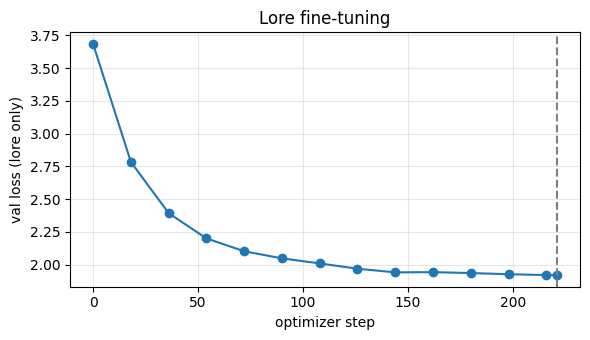

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 3.5)); plt.plot(*zip(*history), "o-"); plt.axvline(best[1], ls="--", c="gray")
plt.xlabel("optimizer step"); plt.ylabel("val loss (lore only)"); plt.title("Lore fine-tuning"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "lore_val_loss.png"), dpi=120); plt.show()

## 5. "After": the same unseen tag lines
Scores (higher is better unless noted):
- **passes_all_checks** — right length, uses the name and every linked name, ship logs start with "Day N." in first person, no franchise terms.
- **uses_name** — the entity's name appears.
- **distinct_4grams** — share of unique 4-word phrases across all outputs (variety; the teacher's value is the reference).
- **top_opening_share** — how often the single most common 3-word opening appears (**lower** is better).

In [10]:
torch.manual_seed(0)
after_texts = [write(model, e) for e in EVAL]
after = score(EVAL, after_texts)
print(f"{'metric':20s} {'base':>8s} {'fine-tuned':>11s} {'teacher':>8s}")
for k in after:
    print(f"{k:20s} {before[k]:8.3f} {after[k]:11.3f} {teacher_ref[k]:8.3f}")

with open(os.path.join(OUT_DIR, "samples.md"), "w", encoding="utf-8") as f:
    for e, b, a in zip(EVAL, before_texts, after_texts):
        probs = lore_schema.check_lore(S, e, a)
        f.write(f"### {e['type']}\n`{lore_schema.to_tags(e)}`\n\n**fine-tuned:** {a}\n\n"
                f"_{'✅ passes all checks' if not probs else '⚠ ' + '; '.join(probs)}_\n\n**base:** {b[:300]}\n\n")
shown = set()
for e, a in zip(EVAL, after_texts):
    if e["type"] in shown or len(shown) >= 5: continue
    shown.add(e["type"]); probs = lore_schema.check_lore(S, e, a)
    print(f"\n▶ {lore_schema.to_tags(e)}\n{a}\n{'✅' if not probs else '⚠ ' + '; '.join(probs)}")

metric                   base  fine-tuned  teacher
passes_all_checks       0.133       0.933    1.000
uses_name               0.533       0.978    1.000
distinct_4grams         0.724       0.970    0.942
top_opening_share       0.111       0.067    0.021
median_words          173.000     119.000  117.000

▶ type: planet | name: Oris | climate: tidally locked | size: giant | life: none | danger: extreme | feature: a strange repeating signal | mood: melancholic | located_in: Morenae | length: short
Oris, a giant tidally locked planet in the Morenae system, is a world of stark contrasts. Its dayside is perpetually bathed in sunlight, while the nightside hosts a thick, toxic atmosphere that glows with eerie green hues. The night side, on the other hand, remains shrouded in perpetual twilight. What makes Oris truly memorable are the strange repeating signal emanating from its polar regions—a haunting, rhythmic pulse that seems to shift and change with each passing hour. This unexplained phe

## 6. Export for your PC
Everything Lore Forge needs, in one zip (~200 MB). The last lines load the export exactly the way the app does and forge one planet — if it prints lore, the zip works.

In [11]:
EXPORT = os.path.join(OUT_DIR, "export"); os.makedirs(EXPORT, exist_ok=True)
torch.save({"model": {k: v.half() for k, v in model.state_dict().items()}, "config": pre["config"],
            "special_tokens": SP, "chat_format": manifest["chat_format"], "arch": "transformer_v2_lore"},
           os.path.join(EXPORT, "model.pt"))
for f in ("model_v2.py", "lore_schema.py", "lore_forge.py", "world_schema.json"): shutil.copy(f, EXPORT)
shutil.copy(os.path.join(DATA_DIR, "tokenizer.json"), EXPORT)
results = {"data": {"kept": len(kept), "dropped": dict(reasons), "per_type": dict(per_type), "opening_cap": cap},
           "train": {"conversations": len(train_set), "qa_mixed_in": len(qa_set), "tokens": n_tok, "cfg": CFG,
                     "best_step": best[1], "best_val_loss": best[0], "val_history": history},
           "scores": {"base": before, "fine_tuned": after, "teacher": teacher_ref}}
json.dump(results, open(os.path.join(OUT_DIR, "results.json"), "w"), indent=1)
shutil.copy(os.path.join(OUT_DIR, "results.json"), EXPORT)
with open(os.path.join(EXPORT, "README.txt"), "w") as f:
    f.write("Lore Forge — space lore from your own 100M model.\n\n"
            "pip install torch --index-url https://download.pytorch.org/whl/cu126\npip install gradio tokenizers\n"
            "python lore_forge.py          (web app at http://127.0.0.1:7860)\npython lore_forge.py --cli    (terminal)\n")
zip_path = shutil.make_archive(os.path.join(OUT_DIR, "lore_forge_export"), "zip", EXPORT)
print(f"export: {zip_path} ({os.path.getsize(zip_path)/1e6:.0f} MB)")

sys.path.insert(0, EXPORT)
import lore_forge; importlib.reload(lore_forge)
eng = lore_forge.LoreEngine(EXPORT, dev)
tags = lore_schema.to_tags(eng.random_entity("planet"))
text = eng.generate(tags)
print(f"export self-check ▶ {tags}\n{text}\n", "✅" if not eng.check(tags, text) else "⚠ " + "; ".join(eng.check(tags, text)))
_, items_sys = lore_forge.star_system_items(eng)
print("star-system generator links:", [(t, e["name"], {k: e[k] for k in ("located_in", "homeworld") if k in e}) for t, e in items_sys][:4])

export: /kaggle/working/lore_sft/lore_forge_export.zip (233 MB)
Loaded 101M-parameter lore model on cuda
export self-check ▶ type: planet | name: Drena Minor | climate: volcanic | size: giant | life: none | danger: medium | feature: ancient ruins | mood: desolate | located_in: Beliix Cluster | length: short
Drena Minor, a colossal planet located in the Beliix Cluster, looms over its moons like a jagged sentinel. Its surface is a chaotic tapestry of molten rivers and towering volcanoes, their fury echoing through the ash-covered sky. The atmosphere, thick with sulfuric clouds, shimmers under the twin moons that orbit Drena Minor, casting an eerie glow across the landscape. Despite its inhospitable nature, ancient ruins dot the terrain—mysterious structures buried beneath layers of lava and rock, their purpose now lost to time. This desolate world, while dangerous, holds secrets that could rewrite our understanding of the universe's origins.
 ✅
star-system generator links: [('Star system